Title: VERS_Detection_fut.ipynb

Purpose: Identifiy Low Energy Events with varying lengths from the model output data under warming conditions

Author: Onno Nennecke on 21.03.2025 Modified: 24.02.2026

Input data: 

- final model output
    - This file lies here: '/climca/people/onennecke/model_output/not_bias_corrected/model_output_all_future.nc'

Output data:

- LEE Tables: LEE_dat_14_fut.csv, LEE_dat_7_fut.csv, LEE_dat_fut.csv, LEE_dat_14_selection_fut.csv, LEE_dat_7_selection_fut.csv, LEE_vl_fut.csv
    - This file lies here: '/climca/people/onennecke/model_output/LEE_detection/'

In [1]:
# Importing libraries
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
import os
import glob


### Read Model output data

In [2]:
path = '/climca/people/onennecke/model_output/not_bias_corrected/model_output_all_future.nc'

ts_datasets = xr.open_dataset(path)
ts_datasets.load()

<xarray.Dataset> Size: 59MB
Dimensions:        (ESM_run: 192, time: 3650)
Coordinates:
    crs            int64 8B 4326
    gridtype       <U6 24B 'lonlat'
    ESM            (ESM_run) <U13 10kB 'ACCESS-CM2' ... 'UKESM1-0-LL'
    run            (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r8i1p1f2'
  * ESM_run        (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'UKESM1-0-LL...
    country        float64 8B 9.0
    period         <U4 16B 'week'
  * time           (time) datetime64[ns] 29kB 2039-01-01 ... 2048-12-31
    doy            (time) int64 29kB 1 2 3 4 5 6 7 ... 360 361 362 363 364 365
Data variables:
    temp           (ESM_run, time) float64 6MB 1.208 -0.303 ... 6.245 7.776
    demand         (ESM_run, time) float64 6MB 1.505e+03 1.524e+03 ... 1.422e+03
    sfcWind        (ESM_run, time) float64 6MB 4.406 6.058 5.642 ... 6.601 8.858
    rsds           (ESM_run, time) float32 3MB 23.72 30.12 26.28 ... 32.49 20.75
    tas            (ESM_run, time) float32 3MB 1.553 0.233 ... 6.191 7.687
    tasmax         (ESM_run, time) float32 3MB 2.524 1.048 ... 9.226 9.364
    wind_off_prod  (ESM_run, time) float64 6MB 92.24 77.15 30.34 ... 166.3 147.1
    wind_on_prod   (ESM_run, time) float64 6MB 153.1 321.4 ... 539.8 1.166e+03
    solar_prod     (ESM_run, time) float64 6MB 38.47 53.53 46.18 ... 61.05 37.61
    total_prod     (ESM_run, time) float64 6MB 283.8 452.1 ... 767.1 1.351e+03
    Netto          (ESM_run, time) float64 6MB -1.221e+03 -1.072e+03 ... -71.73
    Residual_load  (ESM_run, time) float64 6MB 1.221e+03 1.072e+03 ... 71.73

#### Identification of low energy events

In [3]:
# RL = ts_datasets['Residual_load_adj']
RL = ts_datasets['Residual_load']

RL.values

array([[1221.20013817, 1071.59187726, 1250.71236328, ..., 1124.18602803,
        1314.31349002, 1291.64656601],
       [1236.05905651, 1028.26014001,  859.23223506, ..., 1200.41834566,
        1364.94718233, 1281.12595676],
       [ 958.52142067,  762.15764943,  424.02704545, ...,  993.32481832,
         955.29524753,  721.85881236],
       ...,
       [  -6.01077866,  382.37037722,  319.39666533, ...,  948.5305033 ,
         523.1708532 ,  580.68592875],
       [1544.47081279, 1272.66468121,  766.56365913, ...,  989.08750978,
        1239.88797735,  934.47109452],
       [ 131.16803645,  280.03751942,  555.75631081, ..., 1106.66151732,
         674.92395871,   71.73037994]])

In [4]:
# Calculate the rolling means
ts_datasets['RL_mov_avg_7'] = RL_mov_avg_7 = RL.rolling(time=7, center=False).mean()
ts_datasets['RL_mov_avg_14'] = RL_mov_avg_14 = RL.rolling(time=14, center=False).mean()
ts_datasets.load()

<xarray.Dataset> Size: 70MB
Dimensions:        (ESM_run: 192, time: 3650)
Coordinates:
    crs            int64 8B 4326
    gridtype       <U6 24B 'lonlat'
    ESM            (ESM_run) <U13 10kB 'ACCESS-CM2' ... 'UKESM1-0-LL'
    run            (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r8i1p1f2'
  * ESM_run        (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'UKESM1-0-LL...
    country        float64 8B 9.0
    period         <U4 16B 'week'
  * time           (time) datetime64[ns] 29kB 2039-01-01 ... 2048-12-31
    doy            (time) int64 29kB 1 2 3 4 5 6 7 ... 360 361 362 363 364 365
Data variables: (12/14)
    temp           (ESM_run, time) float64 6MB 1.208 -0.303 ... 6.245 7.776
    demand         (ESM_run, time) float64 6MB 1.505e+03 1.524e+03 ... 1.422e+03
    sfcWind        (ESM_run, time) float64 6MB 4.406 6.058 5.642 ... 6.601 8.858
    rsds           (ESM_run, time) float32 3MB 23.72 30.12 26.28 ... 32.49 20.75
    tas            (ESM_run, time) float32 3MB 1.553 0.233 ... 6.191 7.687
    tasmax         (ESM_run, time) float32 3MB 2.524 1.048 ... 9.226 9.364
    ...             ...
    solar_prod     (ESM_run, time) float64 6MB 38.47 53.53 46.18 ... 61.05 37.61
    total_prod     (ESM_run, time) float64 6MB 283.8 452.1 ... 767.1 1.351e+03
    Netto          (ESM_run, time) float64 6MB -1.221e+03 -1.072e+03 ... -71.73
    Residual_load  (ESM_run, time) float64 6MB 1.221e+03 1.072e+03 ... 71.73
    RL_mov_avg_7   (ESM_run, time) float64 6MB nan nan nan ... 380.5 484.8 507.2
    RL_mov_avg_14  (ESM_run, time) float64 6MB nan nan nan ... 421.0 406.6 315.0

##### Threshold Calculation

In [5]:
# thresh_perc = 0.9
# thresh_perc = 0.95
thresh_perc = 0.99

In [6]:
# Select all ESM_runs with period 'week'
ts_datasets_week = ts_datasets.copy()
# RL_week = ts_datasets_week['Residual_load_adj']
RL_week = ts_datasets_week['Residual_load']
threshold_week = np.quantile(RL_week.values.flatten(), thresh_perc)
threshold_week

np.float64(1401.886888221012)

### Use threshold from earlier time period

In [7]:
# threshold_week = np.float64(1319.138650687668) # 95th percentile
threshold_week = np.float64(1410.1543371657242) # 99th percentile


threshold_week

np.float64(1410.1543371657242)

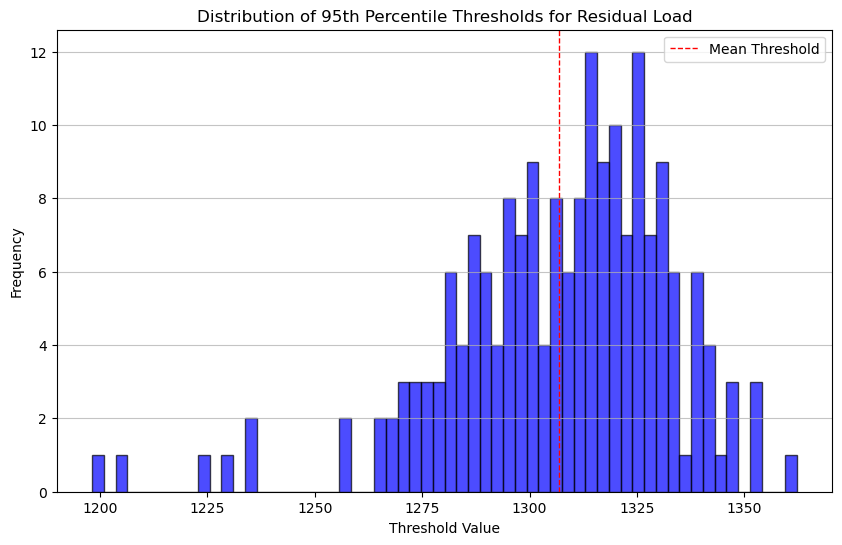

In [10]:
# Test
threshs = []
for esm_run in ts_datasets.ESM_run.values:
    ts_datasets_tst = ts_datasets.sel(ESM_run=esm_run)
    # RL_tst = ts_datasets_tst['Residual_load_adj']
    RL_tst = ts_datasets_tst['Residual_load']
    threshold_tst = np.quantile(RL_tst.values.flatten(), thresh_perc)
    threshs.append(threshold_tst)

# Plot the thresholds as a distribution
plt.figure(figsize=(10, 6))
plt.hist(threshs, bins=60, color='blue', alpha=0.7, edgecolor='black')
plt.title('Distribution of 95th Percentile Thresholds for Residual Load')
plt.xlabel('Threshold Value')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.axvline(np.mean(threshs), color='red', linestyle='dashed', linewidth=1, label='Mean Threshold')
plt.legend()
plt.show()

In [8]:
# Time series of "True" when threshold is exceeded, "False" otherwise

exceed_bool_1 = xr.where(RL > threshold_week, True, False)
exceed_bool_7 = xr.where(RL_mov_avg_7 > threshold_week, True, False)
exceed_bool_14 = xr.where(RL_mov_avg_14 > threshold_week, True, False)

In [9]:
# Look for events without any rolling mean


# Count number of true values overall
count_exceed_1 = exceed_bool_1.sum(dim='time').sum(dim='ESM_run')
count_exceed_1.values
# exceed_bool_1.time
# np.zeros_like(exceed_bool_1, dtype=int)

array(5564)

### Days above threshold (dat) 

- Take each day as its own event (not really events but just days above threshold)

In [10]:
# 1) Extract the flat indices where mask is True
run_idx, time_idx = np.nonzero(exceed_bool_1.values)
n_dat = run_idx.size

# 2) Create a flat counter 1…n_dat
labels = np.arange(1, n_dat + 1, dtype=int)

# 3) Scatter them back into an integer array of same shape
dat = np.zeros_like(exceed_bool_1.values, dtype=int)
dat[run_idx, time_idx] = labels

# wrap back into an xarray
dat = xr.DataArray(
    dat,
    coords=exceed_bool_1.coords,
    dims=exceed_bool_1.dims,
    name="dat"
)

n_dat = n_dat
dat

<xarray.DataArray 'dat' (ESM_run: 192, time: 3650)> Size: 6MB
array([[   0,    0,    0, ...,    0,    0,    0],
       [   0,    0,    0, ...,    0,    0,    0],
       [   0,    0,    0, ...,    0,    0,    0],
       ...,
       [   0,    0,    0, ...,    0,    0,    0],
       [5450,    0,    0, ...,    0,    0,    0],
       [   0,    0,    0, ...,    0,    0,    0]])
Coordinates:
    crs       int64 8B 4326
    gridtype  <U6 24B 'lonlat'
    ESM       (ESM_run) <U13 10kB 'ACCESS-CM2' 'ACCESS-CM2' ... 'UKESM1-0-LL'
    run       (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r7i1p1f2' 'r8i1p1f2'
  * ESM_run   (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'UKESM1-0-LL_r8i1...
    country   float64 8B 9.0
    period    <U4 16B 'week'
  * time      (time) datetime64[ns] 29kB 2039-01-01 2039-01-02 ... 2048-12-31
    doy       (time) int64 29kB 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365

In [11]:
# 1) Extract the flat indices where mask is True
run_idx, time_idx = np.nonzero(exceed_bool_7.values)
n_dat_7 = run_idx.size

# 2) Create a flat counter 1…n_dat_7
labels = np.arange(1, n_dat_7 + 1, dtype=int)

# 3) Scatter them back into an integer array of same shape
dat_7 = np.zeros_like(exceed_bool_7.values, dtype=int)
dat_7[run_idx, time_idx] = labels

# wrap back into an xarray
dat_7 = xr.DataArray(
    dat_7,
    coords=exceed_bool_7.coords,
    dims=exceed_bool_7.dims,
    name="dat_7"
)

n_dat_7 = n_dat_7
dat_7

<xarray.DataArray 'dat_7' (ESM_run: 192, time: 3650)> Size: 6MB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    crs       int64 8B 4326
    gridtype  <U6 24B 'lonlat'
    ESM       (ESM_run) <U13 10kB 'ACCESS-CM2' 'ACCESS-CM2' ... 'UKESM1-0-LL'
    run       (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r7i1p1f2' 'r8i1p1f2'
  * ESM_run   (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'UKESM1-0-LL_r8i1...
    country   float64 8B 9.0
    period    <U4 16B 'week'
  * time      (time) datetime64[ns] 29kB 2039-01-01 2039-01-02 ... 2048-12-31
    doy       (time) int64 29kB 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365

In [12]:
# 1) Extract the flat indices where mask is True
run_idx, time_idx = np.nonzero(exceed_bool_14.values)
n_dat_14 = run_idx.size

# 2) Create a flat counter 1…n_dat_14
labels = np.arange(1, n_dat_14 + 1, dtype=int)

# 3) Scatter them back into an integer array of same shape
dat_14 = np.zeros_like(exceed_bool_14.values, dtype=int)
dat_14[run_idx, time_idx] = labels

# wrap back into an xarray
dat_14 = xr.DataArray(
    dat_14,
    coords=exceed_bool_14.coords,
    dims=exceed_bool_14.dims,
    name="dat_14"
)

n_dat_14 = n_dat_14
dat_14

<xarray.DataArray 'dat_14' (ESM_run: 192, time: 3650)> Size: 6MB
array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])
Coordinates:
    crs       int64 8B 4326
    gridtype  <U6 24B 'lonlat'
    ESM       (ESM_run) <U13 10kB 'ACCESS-CM2' 'ACCESS-CM2' ... 'UKESM1-0-LL'
    run       (ESM_run) <U12 9kB 'r1i1p1f1' 'r4i1p1f1' ... 'r7i1p1f2' 'r8i1p1f2'
  * ESM_run   (ESM_run) <U23 18kB 'ACCESS-CM2_r1i1p1f1' ... 'UKESM1-0-LL_r8i1...
    country   float64 8B 9.0
    period    <U4 16B 'week'
  * time      (time) datetime64[ns] 29kB 2039-01-01 2039-01-02 ... 2048-12-31
    doy       (time) int64 29kB 1 2 3 4 5 6 7 8 ... 359 360 361 362 363 364 365

### Events with rolling mean of 1 above threshold (events_vl) = events with varying length 

In [13]:
# Look for events without any rolling mean

events_vl = np.zeros_like(exceed_bool_1, dtype=int)

# Starting value for the labels
current_label = 1
counter = 0
for run in exceed_bool_1.ESM_run.values:
    run_data = exceed_bool_1.sel(ESM_run=run)
    # Only label this section
    labeled_segment, num_features = ndimage.label(run_data.values)

    if num_features > 0:
        labeled_segment[labeled_segment > 0] += current_label - 1
        current_label += num_features

    # Save the label to the result array
    events_vl[counter] = labeled_segment
    counter += 1

n_events_vl = current_label - 1
n_events_vl



3471

In [14]:
def LEE_detection(events, n_events, t=RL['time'].values, dur = 7, minDuration=1):
    LEE_records = []

    for i in range(len(RL.ESM_run)):
        for ev in range(1, n_events + 1):
            event_duration = (events[i] == ev).sum()
            if event_duration < minDuration:
                continue
            print(f"Processing event {ev} for run {i+1}/{len(RL.ESM_run)}")

            end_idx = np.where(events[i] == ev)[0][0]
            start_idx = end_idx - dur + 1

            date_start = t[start_idx]
            date_end = t[end_idx]

            LEE_start = np.where(t == date_start)[0][0]
            LEE_end = np.where(t == date_end)[0][0]

            RL_run = RL.sel(ESM_run=RL.ESM_run[i]).values
            RL_LEE = RL_run[LEE_start:LEE_end + 1]
            LEE_peak = np.argmax(RL_LEE)

            record = {
                'date_start': date_start,
                'date_end': date_end,
                'date_peak': date_start + LEE_peak,
                # 'date_start_old': RL['old_time'][i][LEE_start].values,
                # 'date_end_old': RL['old_time'][i][LEE_end].values,
                # 'date_peak_old': RL['old_time'][i][LEE_start + LEE_peak].values,
                'index_start': LEE_start,
                'index_end': LEE_end,
                'index_peak': LEE_start + LEE_peak,
                'duration': len(RL_LEE),
                'RL_max': RL_LEE[LEE_peak],
                'RL_mean': RL_LEE.mean(),
                'RL_var': np.sqrt(RL_LEE.var()),
                'RL_cumulative': RL_LEE.sum(),
                'event': ev,
                'ESM': str(RL.ESM[i].values),
                'ESM_run': str(RL.ESM_run[i].values),
                'year': RL.time.dt.year[start_idx].values,
                'doy' : RL.doy[start_idx].values#,
                # 'winter': RL.winter_year[start_idx].values,
                # 'day_of_winter': RL.day_of_winter[start_idx].values
            }

            # # Optional additional metrics if available
            # # (you could generalize this to loop over var names too)
            # for var in ['prod', 'demand', 'pot']:
            #     try:
            #         var_data = RL[var].sel(ESM_run=RL.ESM_run[i]).values[LEE_start:LEE_end + 1]
            #         record[f'{var}_max'] = var_data.max()
            #         record[f'{var}_mean'] = var_data.mean()
            #         record[f'{var}_var'] = np.sqrt(var_data.var())
            #         record[f'{var}_cumulative'] = var_data.sum()
            #     except KeyError:
            #         pass  # Variable doesn't exist, skip

            LEE_records.append(record)

    return pd.DataFrame(LEE_records)


In [15]:
LEE_dat = LEE_detection(dat, n_dat, dur = 1)

Processing event 1 for run 1/192
Processing event 2 for run 1/192
Processing event 3 for run 1/192
Processing event 4 for run 1/192
Processing event 5 for run 1/192
Processing event 6 for run 1/192
Processing event 7 for run 1/192
Processing event 8 for run 1/192
Processing event 9 for run 1/192
Processing event 10 for run 1/192
Processing event 11 for run 1/192
Processing event 12 for run 1/192
Processing event 13 for run 1/192
Processing event 14 for run 1/192
Processing event 15 for run 1/192
Processing event 16 for run 1/192
Processing event 17 for run 1/192
Processing event 18 for run 1/192
Processing event 19 for run 1/192
Processing event 20 for run 1/192
Processing event 21 for run 1/192
Processing event 22 for run 1/192
Processing event 23 for run 1/192
Processing event 24 for run 1/192
Processing event 25 for run 1/192
Processing event 26 for run 1/192
Processing event 27 for run 1/192
Processing event 28 for run 1/192
Processing event 29 for run 1/192
Processing event 30 for

In [16]:
# LEE_dat.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_fut.csv', index=False)
# LEE_dat.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat.csv', index=False)
LEE_dat.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_fut.csv', index=False)

LEE_dat

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2039-11-26,2039-11-26,2039-11-26,329,329,329,1,1421.467551,1421.467551,0.0,1421.467551,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2039,330
1,2039-12-06,2039-12-06,2039-12-06,339,339,339,1,1428.179381,1428.179381,0.0,1428.179381,2,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2039,340
2,2039-12-07,2039-12-07,2039-12-07,340,340,340,1,1415.985518,1415.985518,0.0,1415.985518,3,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2039,341
3,2039-12-28,2039-12-28,2039-12-28,361,361,361,1,1423.007919,1423.007919,0.0,1423.007919,4,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2039,362
4,2041-11-27,2041-11-27,2041-11-27,1060,1060,1060,1,1415.544493,1415.544493,0.0,1415.544493,5,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2041,331
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5559,2047-12-22,2047-12-22,2047-12-22,3275,3275,3275,1,1530.272308,1530.272308,0.0,1530.272308,5560,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,356
5560,2047-12-23,2047-12-23,2047-12-23,3276,3276,3276,1,1520.688314,1520.688314,0.0,1520.688314,5561,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,357
5561,2048-01-16,2048-01-16,2048-01-16,3300,3300,3300,1,1445.614615,1445.614615,0.0,1445.614615,5562,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2048,16
5562,2048-12-02,2048-12-02,2048-12-02,3620,3620,3620,1,1419.256919,1419.256919,0.0,1419.256919,5563,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2048,336


In [17]:
LEE_dat_7 = LEE_detection(dat_7, n_dat_7, dur = 7)

Processing event 1 for run 1/192
Processing event 2 for run 1/192
Processing event 3 for run 1/192
Processing event 4 for run 2/192
Processing event 5 for run 2/192
Processing event 6 for run 2/192
Processing event 7 for run 2/192
Processing event 8 for run 2/192
Processing event 9 for run 2/192
Processing event 10 for run 2/192
Processing event 11 for run 3/192
Processing event 12 for run 3/192
Processing event 13 for run 5/192
Processing event 14 for run 5/192
Processing event 15 for run 5/192
Processing event 16 for run 6/192
Processing event 17 for run 6/192
Processing event 18 for run 6/192
Processing event 19 for run 6/192
Processing event 20 for run 6/192
Processing event 21 for run 6/192
Processing event 22 for run 6/192
Processing event 23 for run 6/192
Processing event 24 for run 6/192
Processing event 25 for run 6/192
Processing event 26 for run 7/192
Processing event 27 for run 7/192
Processing event 28 for run 7/192
Processing event 29 for run 8/192
Processing event 30 for

In [18]:
# If the date_start is the the next day from the line before and they are the same ESM_run they should get the same event number
new_run = LEE_dat_7['ESM_run'].ne(LEE_dat_7['ESM_run'].shift())
not_consecutive = (LEE_dat_7['date_start'] - LEE_dat_7['date_start'].shift()) != pd.Timedelta(days=1)

# Combine them — whenever either is True, that row is the start of a new event
is_new_event = new_run | not_consecutive

# 4. Cum-sum that to get a 1-based event ID
LEE_dat_7['event'] = is_new_event.cumsum()
LEE_dat_7

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2048-12-14,2048-12-20,2048-12-14 00:00:00.000000003,3632,3638,3635,7,1457.672905,1410.505066,37.715503,9873.535461,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2048,348
1,2048-12-15,2048-12-21,2048-12-15 00:00:00.000000006,3633,3639,3639,7,1473.934288,1421.105819,43.223217,9947.740733,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2048,349
2,2048-12-16,2048-12-22,2048-12-16 00:00:00.000000005,3634,3640,3639,7,1473.934288,1417.560443,48.668435,9922.923100,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2048,350
3,2042-12-10,2042-12-16,2042-12-10 00:00:00.000000006,1438,1444,1444,7,1513.572524,1438.465235,48.156933,10069.256648,2,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2042,344
4,2042-12-11,2042-12-17,2042-12-11 00:00:00.000000005,1439,1445,1444,7,1513.572524,1455.361971,39.651434,10187.533798,2,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2042,345
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
542,2043-01-17,2043-01-23,2043-01-17 00:00:00.000000005,1476,1482,1481,7,1514.347132,1414.431912,84.573420,9901.023383,184,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2043,17
543,2043-01-18,2043-01-24,2043-01-18 00:00:00.000000004,1477,1483,1481,7,1514.347132,1420.143573,75.543139,9941.005008,184,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2043,18
544,2047-12-09,2047-12-15,2047-12-09 00:00:00.000000004,3262,3268,3266,7,1483.101572,1422.129382,56.412993,9954.905673,185,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,343
545,2047-12-10,2047-12-16,2047-12-10 00:00:00.000000003,3263,3269,3266,7,1483.101572,1429.889335,42.538207,10009.225347,185,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,344


In [ ]:
LEE_dat_7.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_7_fut.csv', index=False)
# LEE_dat_7.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat_7.csv', index=False)

LEE_dat_7

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2039-12-04,2039-12-10,2039-12-04 00:00:00.000000002,337,343,339,7,1428.179381,1333.555566,74.223781,9334.888962,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2039,338
1,2040-11-16,2040-11-22,2040-11-16 00:00:00.000000006,684,690,690,7,1407.994331,1352.818598,47.145943,9469.730184,2,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2040,320
2,2040-11-17,2040-11-23,2040-11-17 00:00:00.000000005,685,691,690,7,1407.994331,1356.733327,42.624615,9497.133288,2,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2040,321
3,2041-12-17,2041-12-23,2041-12-17 00:00:00.000000003,1080,1086,1083,7,1449.854959,1350.984883,76.019894,9456.894182,3,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2041,351
4,2041-12-18,2041-12-24,2041-12-18 00:00:00.000000002,1081,1087,1083,7,1449.854959,1354.196250,74.787415,9479.373749,3,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2041,352
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9044,2047-12-12,2047-12-18,2047-12-12 00:00:00.000000001,3265,3271,3266,7,1483.101572,1406.259026,74.072143,9843.813185,2104,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,346
9045,2047-12-13,2047-12-19,2047-12-13 00:00:00.000000000,3266,3272,3266,7,1483.101572,1388.328210,72.167915,9718.297470,2104,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,347
9046,2047-12-14,2047-12-20,2047-12-14 00:00:00.000000000,3267,3273,3267,7,1471.279469,1366.491748,62.691025,9565.442234,2104,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,348
9047,2047-12-16,2047-12-22,2047-12-16 00:00:00.000000006,3269,3275,3275,7,1530.272308,1332.560100,127.236141,9327.920700,2105,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,350


In [19]:
# find the index of the row with the highest RL_cumulative in each event
idx = LEE_dat_7.groupby('event')['RL_cumulative'].idxmax()

# select only those rows
LEE_dat_7_max_cum_RL = LEE_dat_7.loc[idx].reset_index(drop=True)
LEE_dat_7_max_cum_RL


,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2048-12-15,2048-12-21,2048-12-15 00:00:00.000000006,3633,3639,3639,7,1473.934288,1421.105819,43.223217,9947.740733,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2048,349
1,2042-12-15,2042-12-21,2042-12-15 00:00:00.000000001,1443,1449,1444,7,1513.572524,1475.015695,19.685854,10325.109863,2,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2042,349
2,2039-12-23,2039-12-29,2039-12-23 00:00:00.000000001,356,362,357,7,1464.796181,1423.488009,35.848441,9964.416060,3,ACCESS-CM2,ACCESS-CM2_r5i1p1f1,2039,357
3,2048-01-27,2048-02-02,2048-01-27 00:00:00.000000000,3311,3317,3311,7,1466.465509,1419.034261,52.717354,9933.239826,4,CESM2,CESM2_LE2-1001_001,2048,27
4,2040-01-11,2040-01-17,2040-01-11 00:00:00.000000006,375,381,381,7,1445.907139,1421.492046,18.850458,9950.444324,5,CESM2,CESM2_LE2-1011_001,2040,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180,2042-01-05,2042-01-11,2042-01-05 00:00:00.000000005,1099,1105,1104,7,1481.250668,1426.832234,53.754538,9987.825640,181,UKESM1-0-LL,UKESM1-0-LL_r7i1p1f2,2042,5
181,2042-12-02,2042-12-08,2042-12-02 00:00:00.000000005,1430,1436,1435,7,1484.665301,1455.371470,31.172508,10187.600293,182,UKESM1-0-LL,UKESM1-0-LL_r7i1p1f2,2042,336
182,2042-12-27,2043-01-02,2042-12-27 00:00:00.000000004,1455,1461,1459,7,1488.296305,1426.913162,47.778501,9988.392132,183,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2042,361
183,2043-01-18,2043-01-24,2043-01-18 00:00:00.000000004,1477,1483,1481,7,1514.347132,1420.143573,75.543139,9941.005008,184,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2043,18


In [20]:
# LEE_dat_7_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat_7_selection.csv', index=False)
# LEE_dat_7_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_7_selection_fut.csv', index=False)
LEE_dat_7_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_7_selection_fut.csv', index=False)




In [21]:
LEE_dat_14 = LEE_detection(dat_14, n_dat_14, dur = 14)

Processing event 1 for run 2/192
Processing event 2 for run 2/192
Processing event 3 for run 2/192
Processing event 4 for run 2/192
Processing event 5 for run 2/192
Processing event 6 for run 6/192


Processing event 7 for run 22/192
Processing event 8 for run 22/192
Processing event 9 for run 22/192
Processing event 10 for run 56/192
Processing event 11 for run 56/192
Processing event 12 for run 56/192
Processing event 13 for run 56/192
Processing event 14 for run 56/192
Processing event 15 for run 60/192
Processing event 16 for run 82/192
Processing event 17 for run 82/192
Processing event 18 for run 86/192
Processing event 19 for run 86/192
Processing event 20 for run 86/192
Processing event 21 for run 86/192
Processing event 22 for run 86/192
Processing event 23 for run 86/192
Processing event 24 for run 86/192
Processing event 25 for run 86/192
Processing event 26 for run 86/192
Processing event 27 for run 86/192
Processing event 28 for run 86/192
Processing event 29 for run 92/192
Processing event 30 for run 92/192
Processing event 31 for run 92/192
Processing event 32 for run 92/192
Processing event 33 for run 92/192
Processing event 34 for run 92/192
Processing event 35 for

In [22]:
# If the date_start is the the next day from the line before and they are the same ESM_run they should get the same event number
new_run = LEE_dat_14['ESM_run'].ne(LEE_dat_14['ESM_run'].shift())
not_consecutive = (LEE_dat_14['date_start'] - LEE_dat_14['date_start'].shift()) != pd.Timedelta(days=1)

# Combine them — whenever either is True, that row is the start of a new event
is_new_event = new_run | not_consecutive

# 4. Cum-sum that to get a 1-based event ID
LEE_dat_14['event'] = is_new_event.cumsum()
# LEE_dat_14

In [33]:
LEE_dat_14.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_14_fut.csv', index=False)
# LEE_dat_14.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat_14.csv', index=False)

LEE_dat_14

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2048-01-05,2048-01-18,2048-01-05 00:00:00.000000008,3289,3302,3297,14,1451.777281,1353.700406,104.604345,18951.805679,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2048,5
1,2048-01-06,2048-01-19,2048-01-06 00:00:00.000000007,3290,3303,3297,14,1451.777281,1363.789375,79.506995,19093.051243,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2048,6
2,2048-01-07,2048-01-20,2048-01-07 00:00:00.000000006,3291,3304,3297,14,1451.777281,1373.937180,72.048732,19235.120521,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2048,7
3,2048-01-08,2048-01-21,2048-01-08 00:00:00.000000005,3292,3305,3297,14,1451.777281,1371.048641,70.097825,19194.680977,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2048,8
4,2048-01-09,2048-01-22,2048-01-09 00:00:00.000000004,3293,3306,3297,14,1451.777281,1330.072112,149.091215,18621.009564,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2048,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3242,2047-12-09,2047-12-22,2047-12-09 00:00:00.000000013,3262,3275,3275,14,1530.272308,1377.344741,108.126753,19282.826373,605,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,343
3243,2047-12-10,2047-12-23,2047-12-10 00:00:00.000000012,3263,3276,3275,14,1530.272308,1392.366248,112.308426,19493.127474,605,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,344
3244,2047-12-11,2047-12-24,2047-12-11 00:00:00.000000011,3264,3277,3275,14,1530.272308,1366.777775,139.662913,19134.888845,605,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,345
3245,2047-12-12,2047-12-25,2047-12-12 00:00:00.000000010,3265,3278,3275,14,1530.272308,1340.522891,161.020398,18767.320479,605,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,346


In [23]:
# find the index of the row with the highest RL_cumulative in each event
idx = LEE_dat_14.groupby('event')['RL_cumulative'].idxmax()

# select only those rows
LEE_dat_14_max_cum_RL = LEE_dat_14.loc[idx].reset_index(drop=True)
LEE_dat_14_max_cum_RL

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2042-12-08,2042-12-21,2042-12-08 00:00:00.000000008,1436,1449,1444,14,1513.572524,1433.873157,55.056281,20074.224199,1,ACCESS-CM2,ACCESS-CM2_r4i1p1f1,2042,342
1,2045-12-13,2045-12-26,2045-12-13 00:00:00.000000004,2536,2549,2540,14,1467.095402,1411.257971,36.197350,19757.611587,2,CESM2,CESM2_LE2-1011_001,2045,347
2,2047-12-20,2048-01-02,2047-12-20 00:00:00.000000006,3273,3286,3279,14,1468.311137,1415.310592,26.885516,19814.348284,3,CESM2,CESM2_LE2-1171_009,2047,354
3,2047-01-07,2047-01-20,2047-01-07 00:00:00.000000002,2926,2939,2928,14,1471.579088,1421.572944,42.000788,19902.021209,4,CESM2,CESM2_LE2-1251_012,2047,7
4,2048-01-06,2048-01-19,2048-01-06 00:00:00.000000001,3290,3303,3291,14,1478.195131,1417.169523,39.947099,19840.373319,5,CESM2,CESM2_LE2-1251_016,2048,6
5,2041-01-13,2041-01-26,2041-01-13 00:00:00.000000005,742,755,747,14,1498.473012,1425.632638,64.236659,19958.856931,6,CESM2,CESM2_LE2-1281_018,2041,13
6,2041-12-05,2041-12-18,2041-12-05 00:00:00.000000011,1068,1081,1079,14,1464.283189,1421.818636,39.201523,19905.460898,7,CESM2,CESM2_LE2-1301_002,2041,339
7,2041-12-13,2041-12-26,2041-12-13 00:00:00.000000012,1076,1089,1088,14,1470.901782,1416.787994,62.535400,19835.031916,8,CESM2,CESM2_LE2-1301_002,2041,347
8,2048-12-14,2048-12-27,2048-12-14 00:00:00.000000005,3632,3645,3637,14,1473.222962,1444.405509,13.729326,20221.677120,9,CESM2,CESM2_LE2-1301_008,2048,348
9,2043-01-15,2043-01-28,2043-01-15 00:00:00.000000000,1474,1487,1474,14,1497.946955,1419.837304,43.576203,19877.722255,10,EC-Earth3,EC-Earth3_r107i1p1f1,2043,15


In [24]:
# LEE_dat_14_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_dat_14_selection.csv', index=False)
# LEE_dat_14_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_14_selection_fut.csv', index=False)
LEE_dat_14_max_cum_RL.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_14_selection_fut.csv', index=False)


### Event detection for variable length

In [25]:
def LEE_detection_vl(events, n_events, t=RL['time'].values, minDuration=1):
    LEE_records = []

    for i in range(len(RL.ESM_run)):
        for ev in range(1, n_events + 1):
            event_duration = (events[i] == ev).sum()
            if event_duration < minDuration:
                continue

            start_idx = np.where(events[i] == ev)[0][0]
            end_idx = np.where(events[i] == ev)[0][-1]

            date_start = t[start_idx]
            date_end = t[end_idx]

            LEE_start = np.where(t == date_start)[0][0]
            LEE_end = np.where(t == date_end)[0][0]

            RL_run = RL.sel(ESM_run=RL.ESM_run[i]).values
            RL_LEE = RL_run[LEE_start:LEE_end + 1]
            LEE_peak = np.argmax(RL_LEE)

            record = {
                'date_start': date_start,
                'date_end': date_end,
                'date_peak': date_start + LEE_peak,
                # 'date_start_old': RL['old_time'][i][LEE_start].values,
                # 'date_end_old': RL['old_time'][i][LEE_end].values,
                # 'date_peak_old': RL['old_time'][i][LEE_start + LEE_peak].values,
                'index_start': LEE_start,
                'index_end': LEE_end,
                'index_peak': LEE_start + LEE_peak,
                'duration': len(RL_LEE),
                'RL_max': RL_LEE[LEE_peak],
                'RL_mean': RL_LEE.mean(),
                'RL_var': np.sqrt(RL_LEE.var()),
                'RL_cumulative': RL_LEE.sum(),
                'event': ev,
                'ESM': str(RL.ESM[i].values),
                'ESM_run': str(RL.ESM_run[i].values),
                'year': RL.time.dt.year[start_idx].values,
                'doy' : RL.doy[start_idx].values#,
                # 'winter': RL.winter_year[start_idx].values,
                # 'day_of_winter': RL.day_of_winter[start_idx].values
            }

            # # Optional additional metrics if available
            # # (you could generalize this to loop over var names too)
            # for var in ['prod', 'demand', 'pot']:
            #     try:
            #         var_data = RL[var].sel(ESM_run=RL.ESM_run[i]).values[LEE_start:LEE_end + 1]
            #         record[f'{var}_max'] = var_data.max()
            #         record[f'{var}_mean'] = var_data.mean()
            #         record[f'{var}_var'] = np.sqrt(var_data.var())
            #         record[f'{var}_cumulative'] = var_data.sum()
            #     except KeyError:
            #         pass  # Variable doesn't exist, skip

            LEE_records.append(record)

    return pd.DataFrame(LEE_records)

In [26]:
LEE_vl = LEE_detection_vl(events_vl, n_events_vl)

In [27]:
# LEE_vl.to_csv('/climca/people/onennecke/model_output/LEE_detection/not_bc_adj/LEE_vl.csv', index=False)
# LEE_vl.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_vl_fut.csv', index=False)
LEE_vl.to_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_vl_99_fut.csv', index=False)


### Adjust years 

In [28]:
# Read this file
warming_thresholds = pd.read_csv('/home/onennecke/CMIP_models/warming_thresholds.csv')
warming_thresholds

,ESM,Year_reached_2C,Absolute_Temp_in_Year_reached_2C,Preindustrial_Temp
0,ACCESS-CM2,2039,15.829328,13.814172
1,BCC-CSM2-MR,2042,16.605910,14.569625
2,CESM2,2044,16.003576,13.996521
3,EC-Earth3,2042,16.024789,13.990722
4,GFDL-ESM4,2050,15.151119,13.140233
5,MPI-ESM1-2-HR,2050,15.885779,13.874228
6,MRI-ESM2-0,2043,15.659036,13.655149
7,KACE-1-0-G,2037,16.196605,14.182940
8,TaiESM1,2040,15.746470,13.692809
9,UKESM1-0-LL,2035,15.469428,13.418571


In [29]:
warming_thresholds['Shift'] = warming_thresholds['Year_reached_2C'] - 2044
warming_thresholds

,ESM,Year_reached_2C,Absolute_Temp_in_Year_reached_2C,Preindustrial_Temp,Shift
0,ACCESS-CM2,2039,15.829328,13.814172,-5
1,BCC-CSM2-MR,2042,16.605910,14.569625,-2
2,CESM2,2044,16.003576,13.996521,0
3,EC-Earth3,2042,16.024789,13.990722,-2
4,GFDL-ESM4,2050,15.151119,13.140233,6
5,MPI-ESM1-2-HR,2050,15.885779,13.874228,6
6,MRI-ESM2-0,2043,15.659036,13.655149,-1
7,KACE-1-0-G,2037,16.196605,14.182940,-7
8,TaiESM1,2040,15.746470,13.692809,-4
9,UKESM1-0-LL,2035,15.469428,13.418571,-9


In [42]:
LEE_dat = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_fut.csv')
LEE_dat_7 = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_7_fut.csv')
LEE_dat_7_max_cum_RL = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_7_selection_fut.csv')
LEE_dat_14 = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_14_fut.csv')
LEE_dat_14_max_cum_RL = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_14_selection_fut.csv')
LEE_vl = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_vl_fut.csv')

tables = [LEE_dat, LEE_dat_7, LEE_dat_7_max_cum_RL, LEE_dat_14, LEE_dat_14_max_cum_RL, LEE_vl]
paths = [
    '/climca/people/onennecke/model_output/LEE_detection/LEE_dat_fut.csv',
    '/climca/people/onennecke/model_output/LEE_detection/LEE_dat_7_fut.csv',
    '/climca/people/onennecke/model_output/LEE_detection/LEE_dat_7_selection_fut.csv',
    '/climca/people/onennecke/model_output/LEE_detection/LEE_dat_14_fut.csv',
    '/climca/people/onennecke/model_output/LEE_detection/LEE_dat_14_selection_fut.csv',
    '/climca/people/onennecke/model_output/LEE_detection/LEE_vl_fut.csv'
]

In [30]:
LEE_dat = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_fut.csv')
LEE_dat_7_max_cum_RL = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_7_selection_fut.csv')
LEE_dat_14_max_cum_RL = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_14_selection_fut.csv')
LEE_vl = pd.read_csv('/climca/people/onennecke/model_output/LEE_detection/LEE_vl_99_fut.csv')

tables = [LEE_dat, LEE_dat_7_max_cum_RL, LEE_dat_14_max_cum_RL, LEE_vl]
paths = [
    '/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_fut.csv',
    '/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_7_selection_fut.csv',
    '/climca/people/onennecke/model_output/LEE_detection/LEE_dat_99_14_selection_fut.csv',
    '/climca/people/onennecke/model_output/LEE_detection/LEE_vl_99_fut.csv'
]

In [31]:

for index, row in LEE_dat.iterrows():
    date_start = row['date_start']
    year = int(date_start[0:4])
    shift = warming_thresholds.loc[warming_thresholds['ESM'] == row['ESM'], 'Shift'].values[0]
    new_year = year + shift
    new_date_start = str(new_year) + date_start[4:]
    LEE_dat.at[index, 'date_start'] = new_date_start

    date_end = row['date_end']
    year = int(date_end[0:4])
    new_year = year + shift
    new_date_end = str(new_year) + date_end[4:]
    LEE_dat.at[index, 'date_end'] = new_date_end

    date_peak = row['date_peak']
    year = int(date_peak[0:4])
    new_year = year + shift
    new_date_peak = str(new_year) + date_peak[4:]
    LEE_dat.at[index, 'date_peak'] = new_date_peak
    # break

LEE_dat

,date_start,date_end,date_peak,index_start,index_end,index_peak,duration,RL_max,RL_mean,RL_var,RL_cumulative,event,ESM,ESM_run,year,doy
0,2034-11-26,2034-11-26,2034-11-26,329,329,329,1,1421.467551,1421.467551,0.0,1421.467551,1,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2039,330
1,2034-12-06,2034-12-06,2034-12-06,339,339,339,1,1428.179381,1428.179381,0.0,1428.179381,2,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2039,340
2,2034-12-07,2034-12-07,2034-12-07,340,340,340,1,1415.985518,1415.985518,0.0,1415.985518,3,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2039,341
3,2034-12-28,2034-12-28,2034-12-28,361,361,361,1,1423.007919,1423.007919,0.0,1423.007919,4,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2039,362
4,2036-11-27,2036-11-27,2036-11-27,1060,1060,1060,1,1415.544493,1415.544493,0.0,1415.544493,5,ACCESS-CM2,ACCESS-CM2_r1i1p1f1,2041,331
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5559,2038-12-22,2038-12-22,2038-12-22,3275,3275,3275,1,1530.272308,1530.272308,0.0,1530.272308,5560,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,356
5560,2038-12-23,2038-12-23,2038-12-23,3276,3276,3276,1,1520.688314,1520.688314,0.0,1520.688314,5561,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2047,357
5561,2039-01-16,2039-01-16,2039-01-16,3300,3300,3300,1,1445.614615,1445.614615,0.0,1445.614615,5562,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2048,16
5562,2039-12-02,2039-12-02,2039-12-02,3620,3620,3620,1,1419.256919,1419.256919,0.0,1419.256919,5563,UKESM1-0-LL,UKESM1-0-LL_r8i1p1f2,2048,336


In [32]:
for i in range(len(tables)):
    table = tables[i]
    print(f"Processing table {i+1}/{len(tables)}")
    path = paths[i]
    for index, row in table.iterrows():
        date_start = row['date_start']
        year = int(date_start[0:4])
        shift = warming_thresholds.loc[warming_thresholds['ESM'] == row['ESM'], 'Shift'].values[0]
        new_year = year + shift
        new_date_start = str(new_year) + date_start[4:]
        table.at[index, 'date_start'] = new_date_start

        date_end = row['date_end']
        year = int(date_end[0:4])
        new_year = year + shift
        new_date_end = str(new_year) + date_end[4:]
        table.at[index, 'date_end'] = new_date_end

        date_peak = row['date_peak']
        year = int(date_peak[0:4])
        new_year = year + shift
        new_date_peak = str(new_year) + date_peak[4:]
        table.at[index, 'date_peak'] = new_date_peak

    table.to_csv(path, index=False)

Processing table 1/4
Processing table 2/4
Processing table 3/4
Processing table 4/4
